In [1]:
# Imports
import pandas as pd
import os
import matplotlib.pyplot as plt
import textwrap

In [2]:
# The notebook runs from cmu_tare_model/, like the main notebook
OUTPUT_FOLDER_PATH = "output_results"
COMPARISON_PATH = os.path.join(
    OUTPUT_FOLDER_PATH, "scenario_results_comparison.csv"
)

# Read time stamps as text, since result file names use them exactly
df_comparison = pd.read_csv(COMPARISON_PATH, dtype={"datetime": str})

# Oldest first (these time stamps sort as text)
RUN_DATETIMES = sorted(df_comparison["datetime"].unique())

print(f"{len(RUN_DATETIMES)} unique run(s): {RUN_DATETIMES}")

3 unique run(s): ['2026-10-30_11-37', '2026-10-30_12-26', '2026-11-02_14-31']


In [3]:
df_comparison.columns

Index(['datetime', 'location', 'description', 'logged at',
       'total homes included (rdu)', 'homes considered for adoption (rdu)',
       'MP', 'Scenario', 'Adopters (rdu)', 'Adopters (% of rdu)',
       'Adopters (% weighted)', 'Annual consumption (GWh)',
       'Absolute annual peak (MW)', 'Summer peak (MW)', 'Winter peak (MW)'],
      dtype='object')

In [4]:
#helper funciton for comparison bar charts
def metric_comparison_bar_chart(
        summary_df,
        metric,
        title = "",
        label_col="scenario",
        xlabel="Scenario",
        rotation=90,
        figsize = (8,5)
        ):

    # A new figure each call, so a loop gives one chart per metric
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.bar(summary_df[label_col], summary_df[metric], color='#4B0082')
    ax.set_title(f'{title} {metric}')
    ax.set_ylabel(metric)
    ax.set_xlabel(xlabel)
    ax.tick_params(axis="x", labelrotation=rotation)
    plt.show()

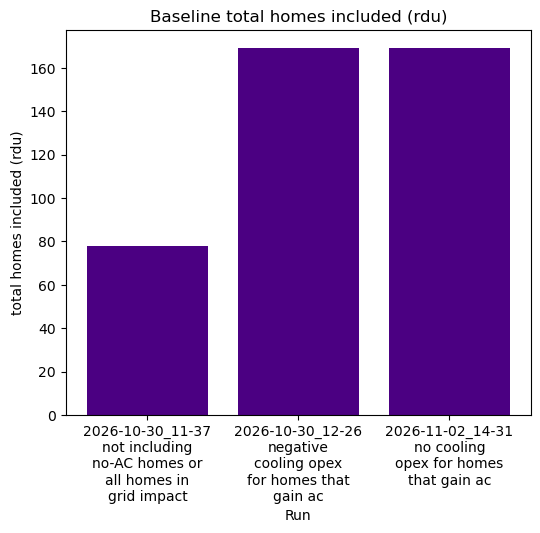

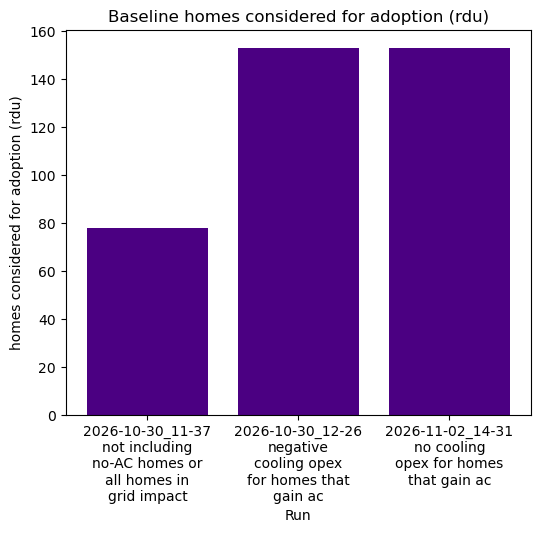

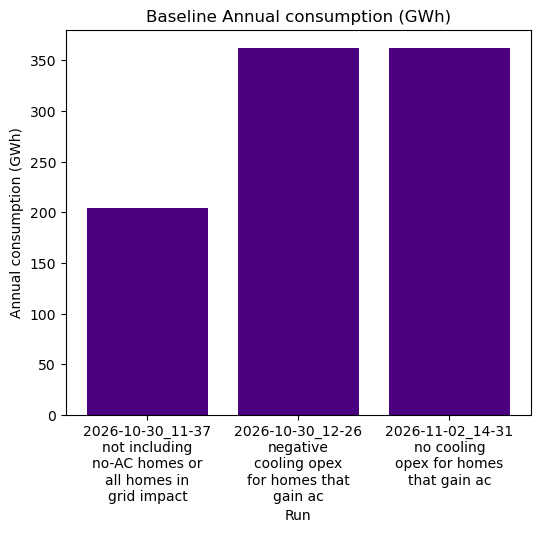

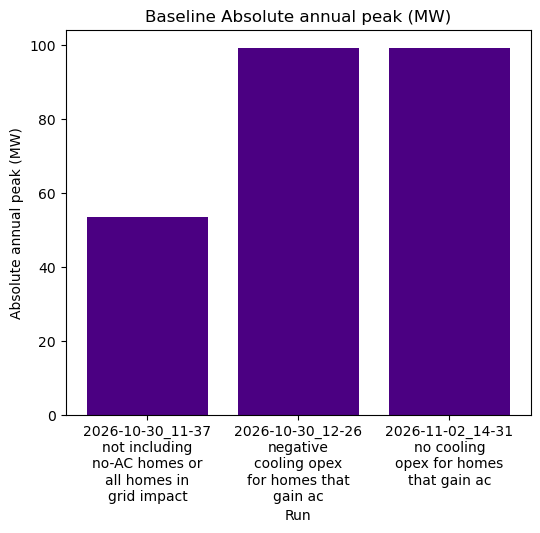

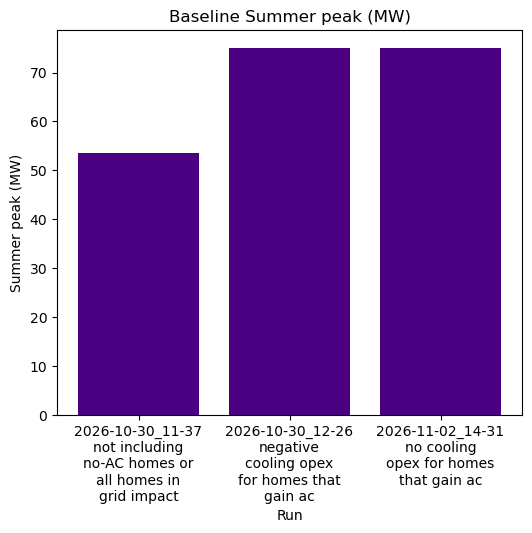

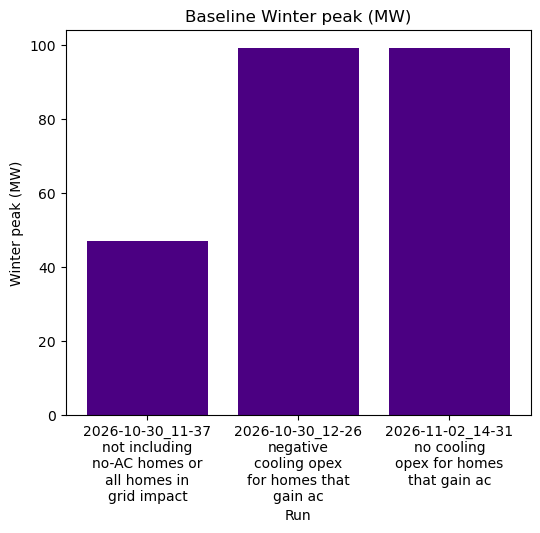

In [5]:
#Compares metrics for baseline scenarios across runs

baseline_metrics = [
    'total homes included (rdu)', 
    'homes considered for adoption (rdu)',
    'Annual consumption (GWh)',
    'Absolute annual peak (MW)', 
    'Summer peak (MW)', 
    'Winter peak (MW)',
]

# A run can be logged more than once; keep its last Baseline row
df_baseline = (
    df_comparison[df_comparison["Scenario"] == "Baseline"]
    .sort_values("logged at")
    .drop_duplicates(subset="datetime", keep="last")
    .sort_values("datetime")
    .reset_index(drop=True)
)

# Creates the labels for hte bar charts
# label - run timestamp and then description 
df_baseline["run_label"] = (
    df_baseline["datetime"]
    + "\n"
    + df_baseline["description"].fillna("").apply(
        lambda text: textwrap.fill(text, 14)
    )
)


for metric in baseline_metrics:
    metric_comparison_bar_chart(
        df_baseline, metric, label_col="run_label", xlabel="Run", rotation=0, title = "Baseline"
    )


In [6]:
#Rebate scenario comparisons 

all_metrics = ['datetime',
           'location', 
           'description', 
           'logged at',   
           'total homes included (rdu)', 
           'homes considered for adoption (rdu)',
           'Adopters (rdu)', 
           'Adopters (% of rdu)',
           'Adopters (% weighted)', 
           'Annual consumption (GWh)',
           'Absolute annual peak (MW)',
           'Summer peak (MW)', 
           'Winter peak (MW)'
]

#Within a given scenario, show how adoption annual energy consumption, and absolute 
#peak change by rebate scenario
metrics = ['Adopters (% of rdu)',
           'Adopters (% weighted)', 
           'Annual consumption (GWh)',
           'Absolute annual peak (MW)',
           ]




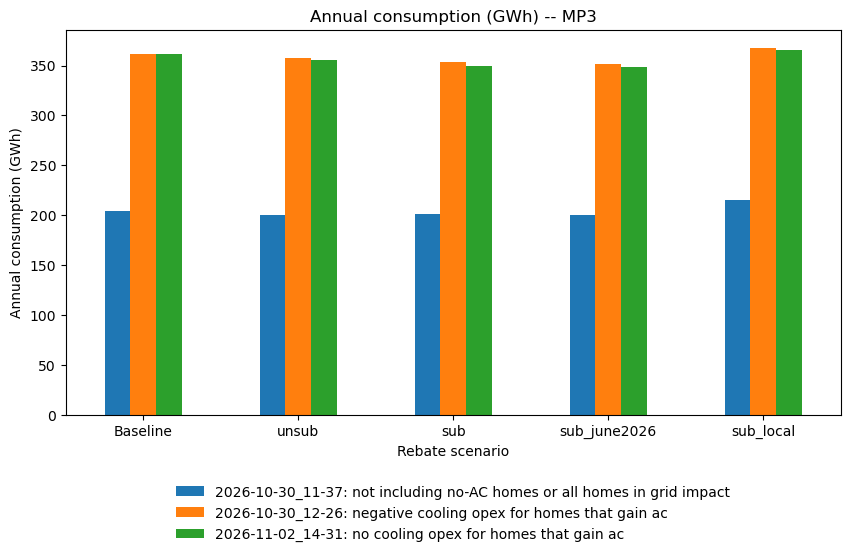

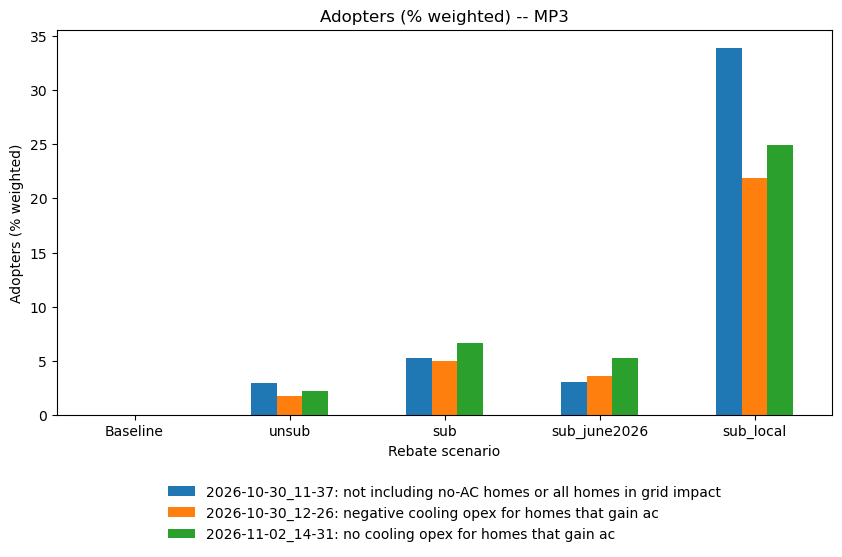

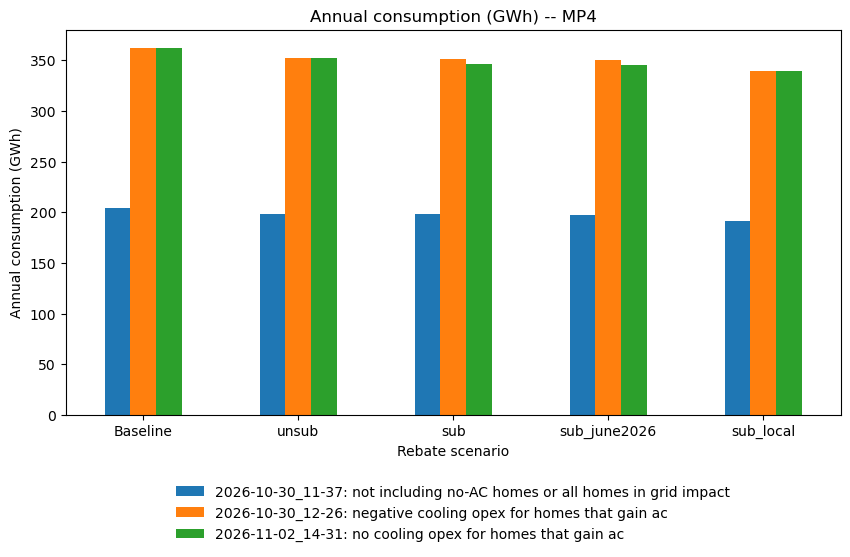

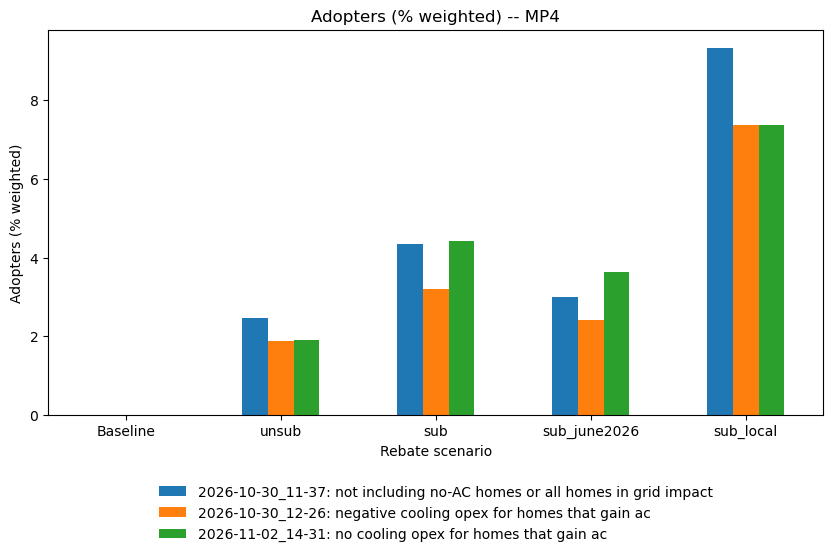

In [8]:

def plot_metric_by_rebate_scenario(df, metric, mp):
    """Clustered bars: one cluster per rebate scenario, one bar per run."""
    # Baseline has no MP, so keep it with every package
    df_plot = df[(df["Scenario"] == "Baseline") | (df["MP"] == mp)].copy()
    df_plot = df_plot[df_plot["Scenario"] != "100pct"]

    # Short cluster names, and a key label for each run
    df_plot["Rebate scenario"] = df_plot["Scenario"].str.replace(
        "heatingSavings_coolingLCC_", ""
    )
    df_plot["Run"] = df_plot["datetime"] + ": " + df_plot["description"]

    # One row per rebate scenario, one column per run
    df_wide = df_plot.pivot(
        index="Rebate scenario", columns="Run", values=metric
    )
    df_wide = df_wide.reindex(
        ["Baseline", "unsub", "sub", "sub_june2026", "sub_local"]
    )

    ax = df_wide.plot.bar(figsize=(10, 5), rot=0)
    ax.set_title(f"{metric} -- MP{mp}")
    ax.set_ylabel(metric)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
    plt.show()


for mp in [3, 4]:
    for metric in ["Annual consumption (GWh)", "Adopters (% weighted)"]:
        plot_metric_by_rebate_scenario(df_comparison, metric, mp)


In [ ]:
SCOPE_ORDER = [
    "heatingSavings_coolingLCC",
    "heatingLCC_coolingSavings",
    "heatingLCC_coolingLCC",
]
REBATE_ORDER = ["unsub", "sub", "sub_june2026", "sub_local"]
ENERGY_METRICS = [
    "Annual consumption (GWh)",
    "Absolute annual peak (MW)",
    "Summer peak (MW)",
    "Winter peak (MW)",
]


def add_comparison_columns(df):
    """Split Scenario into scope and rebate, label runs, add % change."""
    df = df.copy()

    # NPV case names are {heating}_{cooling}_{rebate}
    is_npv_case = ~df["Scenario"].isin(["Baseline", "100pct"])
    parts = df.loc[is_npv_case, "Scenario"].str.split("_", n=2, expand=True)
    df.loc[is_npv_case, "scope"] = parts[0] + "_" + parts[1]
    df.loc[is_npv_case, "rebate"] = parts[2]

    # Baseline has no MP; each MP has its own 100% case
    df["case"] = df["Scenario"]
    is_100pct = df["Scenario"] == "100pct"
    df.loc[is_100pct, "case"] = (
        "MP" + df.loc[is_100pct, "MP"].astype(int).astype(str) + " 100%"
    )

    df["run"] = df["datetime"] + ": " + df["description"]

    # Change from each run's own baseline, so runs of different size compare
    df_base = df[df["Scenario"] == "Baseline"].set_index("datetime")
    for metric in ENERGY_METRICS:
        run_baseline = df["datetime"].map(df_base[metric])
        change_col = metric.split(" (")[0] + " change from baseline (%)"
        df[change_col] = (df[metric] - run_baseline) / run_baseline * 100

    return df


def plot_clustered(df, metric, x, hue, x_order=None, hue_order=None,
                   title=None, baseline=None):
    """Clustered bars: one cluster per value of x, one color per value of hue."""
    df_wide = df.pivot(index=x, columns=hue, values=metric)
    if x_order is not None:
        df_wide = df_wide.reindex(x_order)
    if hue_order is not None:
        df_wide = df_wide.reindex(columns=hue_order)

    ax = df_wide.plot.bar(figsize=(10, 5), rot=0)
    if baseline is not None and pd.notna(baseline):
        ax.axhline(baseline, color="black", linestyle="--", label="Baseline")
    ax.set_title(title or metric)
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
    plt.show()


df_cmp = add_comparison_columns(df_comparison)


In [ ]:
# 1) Baselines and 100% adoption across runs
df_ref = df_cmp[df_cmp["Scenario"].isin(["Baseline", "100pct"])]
for metric in ENERGY_METRICS:
    plot_clustered(df_ref, metric, x="case", hue="run",
                   x_order=["Baseline", "MP3 100%", "MP4 100%"])

# 2) Replacement offset scopes within one run and one MP
run, mp = RUN_DATETIMES[-1], 3
is_run = df_cmp["datetime"] == run
df_run = df_cmp[is_run & (df_cmp["MP"] == mp) & df_cmp["scope"].notna()]
for metric in ENERGY_METRICS + ["Adopters (% weighted)"]:
    run_baseline = df_cmp.loc[
        is_run & (df_cmp["Scenario"] == "Baseline"), metric
    ].item()
    plot_clustered(df_run, metric, x="rebate", hue="scope",
                   x_order=REBATE_ORDER, hue_order=SCOPE_ORDER,
                   title=f"{metric} -- {run}, MP{mp}", baseline=run_baseline)

# 3) Rebate scenarios across runs, for one MP and one scope
scope = "heatingSavings_coolingLCC"
df_scope = df_cmp[(df_cmp["MP"] == mp) & (df_cmp["scope"] == scope)]
for metric in ["Annual consumption change from baseline (%)",
               "Absolute annual peak change from baseline (%)",
               "Adopters (% weighted)"]:
    plot_clustered(df_scope, metric, x="rebate", hue="run",
                   x_order=REBATE_ORDER, title=f"{metric} -- MP{mp}, {scope}")
